In [1]:
import os
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input

np.random.seed(42)
tf.random.set_seed(42)
sns.set_theme(style="whitegrid")

IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 8
DATA_URL = "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip"

In [2]:
zip_path = "cats_dogs.zip"

if not os.path.isdir("PetImages"):
    if not os.path.exists(zip_path):
        subprocess.run(["curl", "-L", "--fail", "-o", zip_path, DATA_URL], check=True)
    subprocess.run(["unzip", "-q", "-o", zip_path], check=True)

print("Cat:", len(os.listdir("PetImages/Cat")))
print("Dog:", len(os.listdir("PetImages/Dog")))

Cat: 12501
Dog: 12501


In [7]:
removed = 0
converted = 0

for folder in ("Cat", "Dog"):
    folder_path = os.path.join("PetImages", folder)
    for fname in os.listdir(folder_path):
        fpath = os.path.join(folder_path, fname)
        if not os.path.isfile(fpath):
            continue
        if not fname.lower().endswith((".jpg", ".jpeg")):
            os.remove(fpath)
            removed += 1
            continue
        try:
            with Image.open(fpath) as im:
                fmt = im.format
                rgb = im.convert("RGB")
                rgb.load()
            if fmt != "JPEG":
                rgb.save(fpath, format="JPEG", quality=95)
                converted += 1
        except Exception:
            os.remove(fpath)
            removed += 1

print("removed:", removed)
print("converted to jpeg:", converted)
print("Cat:", len(os.listdir("PetImages/Cat")))
print("Dog:", len(os.listdir("PetImages/Dog")))

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


removed: 0
converted to jpeg: 229
Cat: 12499
Dog: 12499


,set,samples,cat,dog
0,train,17498,8749,8749
1,validation,3750,1875,1875
2,test,3750,1875,1875


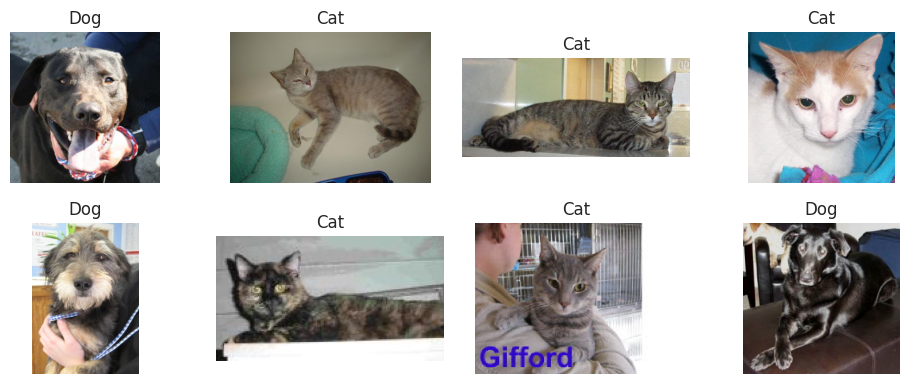

In [8]:
paths, labels = [], []
for label, folder in enumerate(("Cat", "Dog")):
    folder_path = os.path.join("PetImages", folder)
    for fname in sorted(os.listdir(folder_path)):
        paths.append(os.path.join(folder_path, fname))
        labels.append(label)

paths_train, paths_temp, y_train, y_temp = train_test_split(
    paths, labels, test_size=0.30, random_state=42, stratify=labels
)
paths_val, paths_test, y_val, y_test = train_test_split(
    paths_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

split_df = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "samples": [len(y_train), len(y_val), len(y_test)],
    "cat": [y_train.count(0), y_val.count(0), y_test.count(0)],
    "dog": [y_train.count(1), y_val.count(1), y_test.count(1)],
})
display(split_df)

plt.figure(figsize=(10, 4))
for i, (path, label) in enumerate(zip(paths_train[:8], y_train[:8])):
    plt.subplot(2, 4, i + 1)
    plt.imshow(Image.open(path).convert("RGB"))
    plt.title("Dog" if label == 1 else "Cat")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [9]:
def decode(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((list(file_paths), list(file_labels)))
    if training:
        ds = ds.shuffle(2048, seed=42)
    ds = ds.map(decode, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(paths_train, y_train, training=True)
val_ds = make_dataset(paths_val, y_val)
test_ds = make_dataset(paths_test, y_test)

In [10]:
def build_cnn(filters, name):
    model = Sequential(name=name)
    model.add(Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    for units in filters:
        model.add(Conv2D(units, 3, padding="same", activation="relu"))
        model.add(MaxPooling2D(2))
    model.add(Flatten())
    model.add(Dense(128, activation="relu"))
    model.add(Dropout(0.4))
    model.add(Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.MeanSquaredError(name="mse"),
        ],
    )
    return model

configs = [
    {"name": "CNN-2", "filters": [32, 64]},
    {"name": "CNN-3", "filters": [32, 64, 128]},
    {"name": "CNN-4", "filters": [32, 64, 128, 256]},
]

histories = {}
predictions = {}
param_counts = {}
y_test_arr = np.array(y_test)

for cfg in configs:
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)
    model = build_cnn(cfg["filters"], cfg["name"])
    model.summary()
    param_counts[cfg["name"]] = model.count_params()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=2,
    )
    histories[cfg["name"]] = {k: list(v) for k, v in history.history.items()}

    prob = model.predict(test_ds, verbose=0).ravel()
    predictions[cfg["name"]] = (prob >= 0.5).astype(int)
    print("trained:", cfg["name"])

Model: "CNN-2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     8,388,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,408,257 (32.07 MB)

 Trainable params: 8,408,257 (32.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
547/547 - 36s - 66ms/step - accuracy: 0.6321 - loss: 0.6535 - mse: 0.2243 - val_accuracy: 0.7112 - val_loss: 0.5753 - val_mse: 0.1954
Epoch 2/8
547/547 - 22s - 40ms/step - accuracy: 0.7360 - loss: 0.5367 - mse: 0.1792 - val_accuracy: 0.7325 - val_loss: 0.5480 - val_mse: 0.1826
Epoch 3/8
547/547 - 21s - 38ms/step - accuracy: 0.7781 - loss: 0.4640 - mse: 0.1514 - val_accuracy: 0.7483 - val_loss: 0.5261 - val_mse: 0.1712
Epoch 4/8
547/547 - 22s - 39ms/step - accuracy: 0.8222 - loss: 0.3944 - mse: 0.1255 - val_accuracy: 0.7755 - val_loss: 0.4976 - val_mse: 0.1582
Epoch 5/8
547/547 - 41s - 74ms/step - accuracy: 0.8587 - loss: 0.3206 - mse: 0.1005 - val_accuracy: 0.7787 - val_loss: 0.5269 - val_mse: 0.1567
Epoch 6/8
547/547 - 40s - 72ms/step - accuracy: 0.8974 - loss: 0.2480 - mse: 0.0753 - val_accuracy: 0.7965 - val_loss: 0.5631 - val_mse: 0.1543
Epoch 7/8
547/547 - 22s - 40ms/step - accuracy: 0.9253 - loss: 0.1894 - mse: 0.0565 - val_accuracy: 0.7768 - val_loss: 0.6399 - val_mse:

... (8 outputs left out)

 Total params: 2,485,825 (9.48 MB)

 Trainable params: 2,485,825 (9.48 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
547/547 - 33s - 61ms/step - accuracy: 0.5721 - loss: 0.6717 - mse: 0.2393 - val_accuracy: 0.6715 - val_loss: 0.6072 - val_mse: 0.2098
Epoch 2/8
547/547 - 21s - 39ms/step - accuracy: 0.7157 - loss: 0.5549 - mse: 0.1870 - val_accuracy: 0.7765 - val_loss: 0.4812 - val_mse: 0.1556
Epoch 3/8
547/547 - 40s - 73ms/step - accuracy: 0.7756 - loss: 0.4734 - mse: 0.1546 - val_accuracy: 0.8016 - val_loss: 0.4414 - val_mse: 0.1420
Epoch 4/8
547/547 - 22s - 40ms/step - accuracy: 0.8227 - loss: 0.3997 - mse: 0.1268 - val_accuracy: 0.8029 - val_loss: 0.4273 - val_mse: 0.1372
Epoch 5/8
547/547 - 21s - 39ms/step - accuracy: 0.8507 - loss: 0.3401 - mse: 0.1063 - val_accuracy: 0.8392 - val_loss: 0.3614 - val_mse: 0.1142
Epoch 6/8
547/547 - 23s - 42ms/step - accuracy: 0.8840 - loss: 0.2756 - mse: 0.0841 - val_accuracy: 0.8613 - val_loss: 0.3427 - val_mse: 0.1030
Epoch 7/8
547/547 - 40s - 72ms/step - accuracy: 0.9049 - loss: 0.2320 - mse: 0.0699 - val_accuracy: 0.8725 - val_loss: 0.3052 - val_mse:

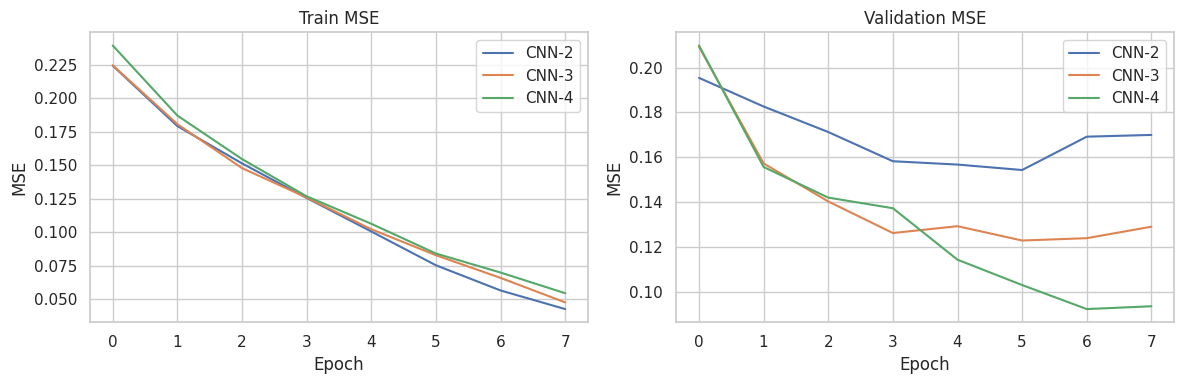

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for name, hist in histories.items():
    plt.plot(hist["mse"], label=name)
plt.title("Train MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()

plt.subplot(1, 2, 2)
for name, hist in histories.items():
    plt.plot(hist["val_mse"], label=name)
plt.title("Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()

plt.tight_layout()
plt.show()

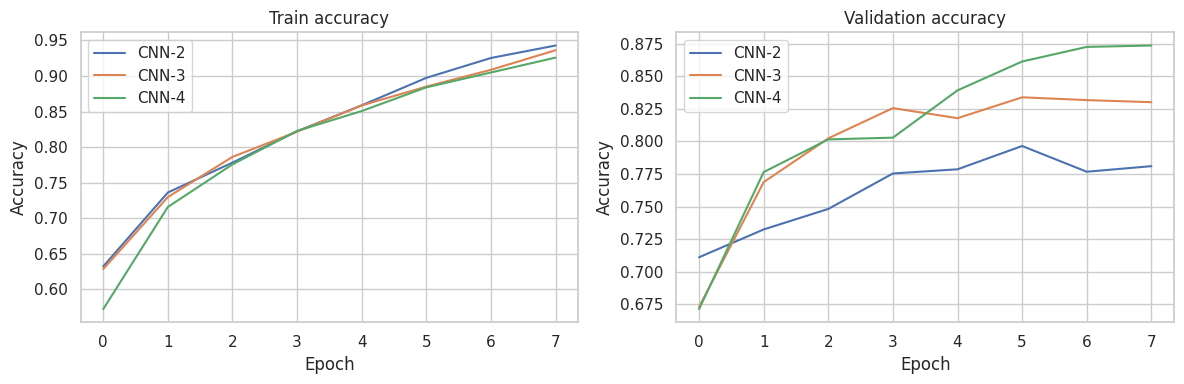

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for name, hist in histories.items():
    plt.plot(hist["accuracy"], label=name)
plt.title("Train accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
for name, hist in histories.items():
    plt.plot(hist["val_accuracy"], label=name)
plt.title("Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
rows = []
cms = {}

for name, y_pred in predictions.items():
    rows.append({
        "Model": name,
        "Conv blocks": int(name.split("-")[1]),
        "Parameters": param_counts[name],
        "Val MSE": histories[name]["val_mse"][-1],
        "Accuracy": accuracy_score(y_test_arr, y_pred),
        "Precision": precision_score(y_test_arr, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test_arr, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_test_arr, y_pred, average="macro", zero_division=0),
    })
    cms[name] = confusion_matrix(y_test_arr, y_pred)

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

for name, y_pred in predictions.items():
    print("\n", name)
    print(classification_report(
        y_test_arr,
        y_pred,
        target_names=["Cat", "Dog"],
        zero_division=0,
    ))

,Conv blocks,Parameters,Val MSE,Accuracy,Precision,Recall,F1-score
Model,,,,,,,
CNN-2,2,8408257,0.1699,0.7885,0.7886,0.7885,0.7885
CNN-3,3,4287809,0.1290,0.8387,0.8397,0.8387,0.8385
CNN-4,4,2485825,0.0935,0.8773,0.8795,0.8773,0.8772



 CNN-2
              precision    recall  f1-score   support

         Cat       0.79      0.78      0.79      1875
         Dog       0.79      0.79      0.79      1875

    accuracy                           0.79      3750
   macro avg       0.79      0.79      0.79      3750
weighted avg       0.79      0.79      0.79      3750


 CNN-3
              precision    recall  f1-score   support

         Cat       0.86      0.81      0.83      1875
         Dog       0.82      0.87      0.84      1875

    accuracy                           0.84      3750
   macro avg       0.84      0.84      0.84      3750
weighted avg       0.84      0.84      0.84      3750


 CNN-4
              precision    recall  f1-score   support

         Cat       0.91      0.84      0.87      1875
         Dog       0.85      0.92      0.88      1875

    accuracy                           0.88      3750
   macro avg       0.88      0.88      0.88      3750
weighted avg       0.88      0.88      0.88      3

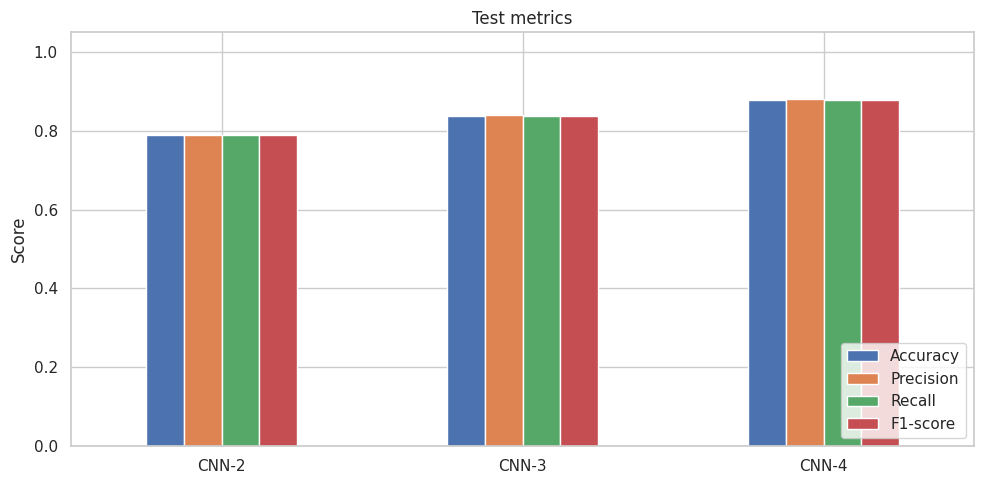

In [14]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]
ax = results[metric_cols].plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_title("Test metrics")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

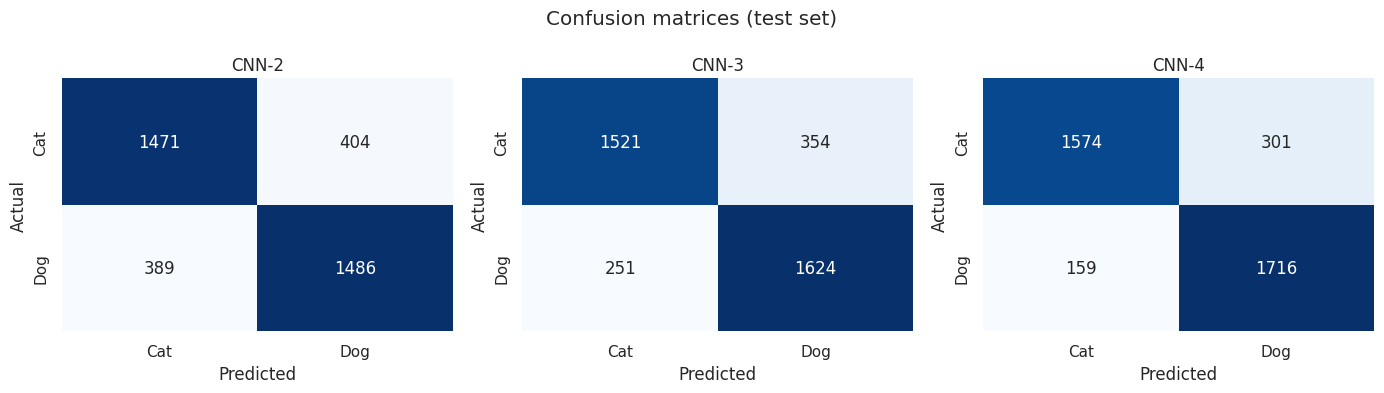

In [15]:
labels = ["Cat", "Dog"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion matrices (test set)")
plt.tight_layout()
plt.show()

In [16]:
best = results["F1-score"].idxmax()
print(best)
display(results.loc[[best]].round(4))

CNN-4


,Conv blocks,Parameters,Val MSE,Accuracy,Precision,Recall,F1-score
Model,,,,,,,
CNN-4,4,2485825,0.0935,0.8773,0.8795,0.8773,0.8772
